# Activity 2: Operation of Sequences
Based on lecture **DSP03 – Operation of Sequences**. Uses the exact examples from the slides.

Requires: `pip install numpy matplotlib`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

def align(n1, x1, n2, x2):
    """Put two sequences on a common n-axis (missing samples = 0)."""
    n = np.arange(min(n1[0], n2[0]), max(n1[-1], n2[-1]) + 1)
    a, b = np.zeros(len(n)), np.zeros(len(n))
    a[n1 - n[0]] = x1
    b[n2 - n[0]] = x2
    return n, a, b

def show(label, nn, yy):
    print(f"{label:34s} n = {nn.tolist()}  y = {yy.tolist()}")

## Reference sequence
`x[n] = {1, 2, 3, 4, 5}` with the origin at **3** (n = -2 … 2)

In [2]:
n = np.arange(-2, 3)
x = np.array([1, 2, 3, 4, 5])
show("x[n]", n, x)

x[n]                               n = [-2, -1, 0, 1, 2]  y = [1, 2, 3, 4, 5]


## 1. Scalar multiplication: y[n] = 2·x[n]

In [3]:
y_scale = 2 * x
show("2x[n]", n, y_scale)

2x[n]                              n = [-2, -1, 0, 1, 2]  y = [2, 4, 6, 8, 10]


## 2. Addition and multiplication
`x1[n] = {1, 2, 3}` origin at 2 (n = -1..1), `x2[n] = {4, 5, 6}` origin at 4 (n = 0..2)

In [4]:
n1, x1 = np.arange(-1, 2), np.array([1, 2, 3])
n2, x2 = np.arange(0, 3),  np.array([4, 5, 6])
n_add, a, b = align(n1, x1, n2, x2)

y_add = a + b      # expected {1, 6, 8, 6}
y_mul = a * b      # expected {0, 8, 15, 0}
show("x1[n] + x2[n]", n_add, y_add)
show("x1[n] * x2[n]", n_add, y_mul)

x1[n] + x2[n]                      n = [-1, 0, 1, 2]  y = [1.0, 6.0, 8.0, 6.0]
x1[n] * x2[n]                      n = [-1, 0, 1, 2]  y = [0.0, 8.0, 15.0, 0.0]


## 3. Time delay, time advance, time reversal

In [5]:
# Delay y[n] = x[n-2]  (right shift)
n_delay = n + 2
# Advance y[n] = x[n+2] (left shift)
n_adv = n - 2
# Reversal y[n] = x[-n]
n_rev, y_rev = -n[::-1], x[::-1]

show("x[n-2]  (delay)", n_delay, x)
show("x[n+2]  (advance)", n_adv, x)
show("x[-n]   (reversal)", n_rev, y_rev)

x[n-2]  (delay)                    n = [0, 1, 2, 3, 4]  y = [1, 2, 3, 4, 5]
x[n+2]  (advance)                  n = [-4, -3, -2, -1, 0]  y = [1, 2, 3, 4, 5]
x[-n]   (reversal)                 n = [-2, -1, 0, 1, 2]  y = [5, 4, 3, 2, 1]


## 4. Composite operation: y[n] = x[-n + k]
Method 1: shift then fold. Method 2: fold then shift. Both must agree.

In [6]:
k = 1
# Method 1: v[n] = x[n+k] (advance), then y[n] = v[-n]
v1_n = n - k
m1_n, m1_y = -v1_n[::-1], x[::-1]
# Method 2: v[n] = x[-n] (fold), then y[n] = v[n-k] (delay)
m2_n, m2_y = n_rev + k, y_rev

assert np.array_equal(m1_n, m2_n) and np.array_equal(m1_y, m2_y)
show(f"x[-n+{k}] (both methods agree)", m1_n, m1_y)

x[-n+1] (both methods agree)       n = [-1, 0, 1, 2, 3]  y = [5, 4, 3, 2, 1]


## Graphs

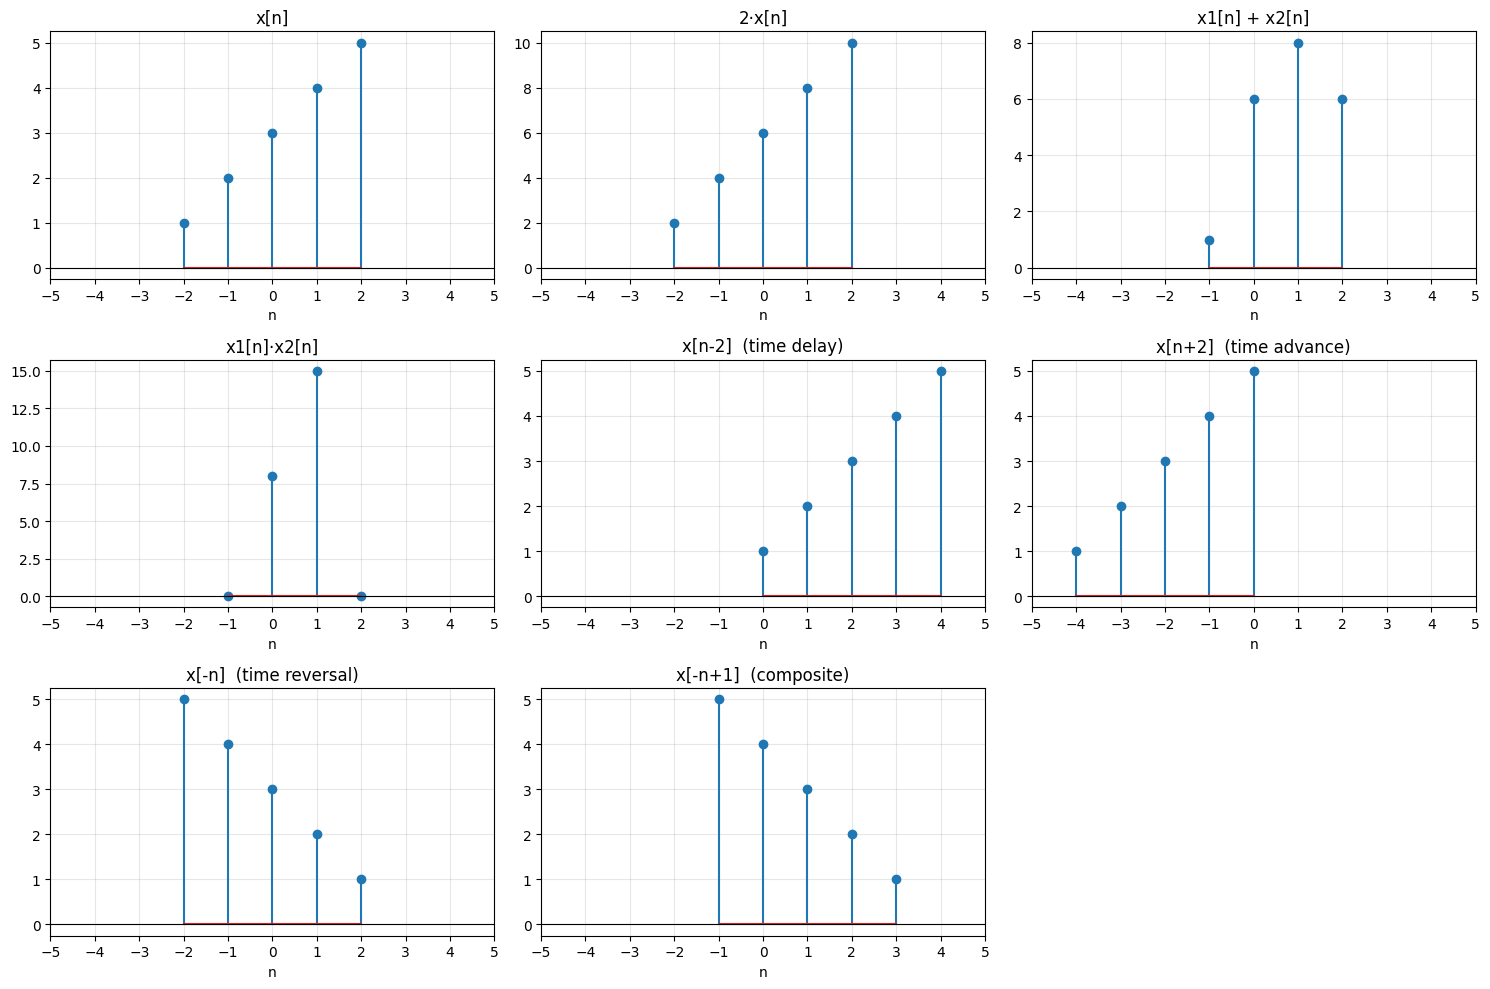

In [7]:
plots = [("x[n]", n, x), ("2·x[n]", n, y_scale),
         ("x1[n] + x2[n]", n_add, y_add), ("x1[n]·x2[n]", n_add, y_mul),
         ("x[n-2]  (time delay)", n_delay, x), ("x[n+2]  (time advance)", n_adv, x),
         ("x[-n]  (time reversal)", n_rev, y_rev), (f"x[-n+{k}]  (composite)", m1_n, m1_y)]

fig, axs = plt.subplots(3, 3, figsize=(15, 10))
for ax, (t, nn, yy) in zip(axs.ravel(), plots):
    ax.stem(nn, yy)
    ax.set_title(t)
    ax.set_xlabel("n")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(-5, 6))
    ax.grid(True, alpha=0.3)
axs.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("activity2_graphs.png", dpi=150)
plt.show()